# 01 · SmartShop EDA: what a rescan is up against

**Question for this project:** which SmartShop sessions should be rescanned, and which items
checked, so each minute of colleague time recovers the most loss while honest shoppers are
stopped as rarely as possible?

This notebook looks at real shopping trips (dunnhumby *The Complete Journey*) through a
SmartShop lens: how big baskets are, where the value sits, which high-risk products appear,
how Nectar Prices change what an unscanned item is worth, when the store is busy, and how much
history each shopper brings.

**What is real here and what is not.** Baskets, prices, member discounts, stores, times and
repeat visits are real. The data has no scan events and no rescan outcomes; those are simulated
from week 3. Amounts are in US dollars, as recorded. Every household in the panel holds a
loyalty card, so non-Nectar shoppers are also simulated later.

In [1]:
import pandas as pd

from smartshop.lines import connect
from smartshop.viz import BLUE, GREY, ORANGE, TEXT_2, money, pct, save, set_style, subtitle
import matplotlib.pyplot as plt

set_style()
con = connect()
q = lambda sql: con.sql(sql).df()

## The scan lines

`scan_lines` keeps the items a shopper would scan: fuel, till-only entries, returns and voids
are removed, and weeks 1–16 (while households were still joining the panel) are dropped, as in
the Nectar project. Each line carries two prices:

- **normal price** (`shelf_value`): what a non-member pays
- **Nectar price** (`nectar_value`): the price with the member discount

In [2]:
q('''
SELECT COUNT(*) AS lines, COUNT(DISTINCT basket_id) AS trips, COUNT(DISTINCT member_id) AS members,
       COUNT(DISTINCT store_id) AS stores, ROUND(SUM(shelf_value)) AS normal_price_total,
       ROUND(SUM(nectar_value)) AS nectar_price_total
FROM scan_lines
''')

,lines,trips,members,stores,normal_price_total,nectar_price_total
0,2348715,230489,2492,532,8065164.0,6817025.0


## 1. Basket size: how much work is a full rescan?

In [3]:
baskets = q('''
SELECT basket_id, COUNT(*) AS lines, SUM(quantity) AS units, SUM(nectar_value) AS value
FROM scan_lines GROUP BY 1
''')
summary = pd.Series({
    'median lines': baskets.lines.median(),
    'p90 lines': baskets.lines.quantile(0.9),
    'median units': baskets.units.median(),
    'median value $': baskets.value.median(),
    'share of trips with 1 line': (baskets.lines == 1).mean(),
    'share of trips with 20+ lines': (baskets.lines >= 20).mean(),
})
summary.round(3)

median lines                      5.000
p90 lines                        26.000
median units                      7.000
median value $                   15.890
share of trips with 1 line        0.145
share of trips with 20+ lines     0.153
dtype: float64

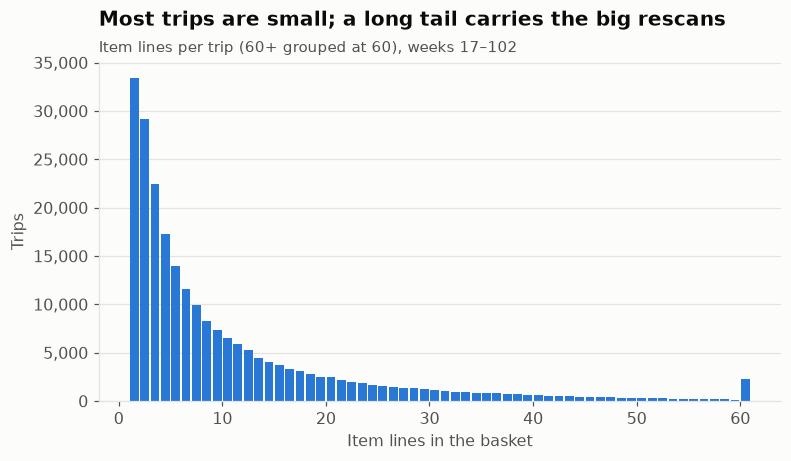

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
clipped = baskets.lines.clip(upper=60)
ax.hist(clipped, bins=range(1, 62), color=BLUE, rwidth=0.85)
ax.set_title('Most trips are small; a long tail carries the big rescans')
subtitle(ax, 'Item lines per trip (60+ grouped at 60), weeks 17–102')
ax.set_xlabel('Item lines in the basket')
ax.set_ylabel('Trips')
ax.yaxis.set_major_formatter(money(0).__class__(lambda x, _p=None: f'{x:,.0f}'))
save(fig, '01_basket_size')
fig

## 2. Where the value sits: is a targeted partial rescan worth it?

A partial rescan today checks a random handful of items. If a few items carry most of the
basket's value, checking the *right* three recovers far more than checking any three.

In [5]:
conc = q('''
WITH r AS (
    SELECT basket_id, nectar_value AS v,
           ROW_NUMBER() OVER (PARTITION BY basket_id ORDER BY nectar_value DESC) AS rk,
           COUNT(*) OVER (PARTITION BY basket_id) AS n,
           SUM(nectar_value) OVER (PARTITION BY basket_id) AS total
    FROM scan_lines
), b AS (
    SELECT basket_id, ANY_VALUE(n) AS n, SUM(v) FILTER (WHERE rk <= 3) / ANY_VALUE(total) AS top3
    FROM r GROUP BY 1
)
SELECT CASE WHEN n < 10 THEN '5–9' WHEN n < 20 THEN '10–19' ELSE '20+' END AS basket_lines,
       COUNT(*) AS trips,
       AVG(3.0 / n) AS random_3_items,      -- expected share of value from 3 random lines
       AVG(top3) AS top_3_by_value
FROM b WHERE n >= 5 GROUP BY 1
''').set_index('basket_lines').loc[['5–9', '10–19', '20+']]
conc['lift'] = conc.top_3_by_value / conc.random_3_items
conc.round(3)

,trips,random_3_items,top_3_by_value,lift
basket_lines,,,,
5–9,51223,0.469,0.688,1.467
10–19,41700,0.229,0.456,1.986
20+,35205,0.099,0.266,2.672


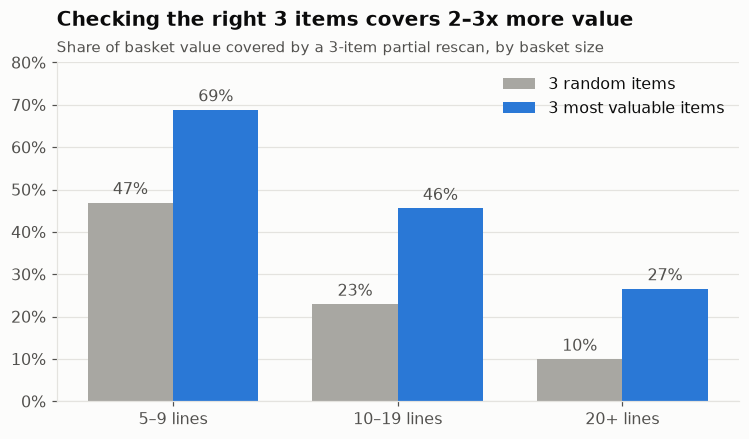

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(conc))
w = 0.38
b1 = ax.bar([i - w / 2 for i in x], conc.random_3_items, w, color=GREY, label='3 random items')
b2 = ax.bar([i + w / 2 for i in x], conc.top_3_by_value, w, color=BLUE, label='3 most valuable items')
for bars in (b1, b2):
    ax.bar_label(bars, labels=[f'{v:.0%}' for v in bars.datavalues], padding=3, color=TEXT_2)
ax.set_xticks(list(x), [f'{k} lines' for k in conc.index])
ax.yaxis.set_major_formatter(pct())
ax.set_ylim(0, 0.8)
ax.set_title('Checking the right 3 items covers 2–3x more value')
subtitle(ax, 'Share of basket value covered by a 3-item partial rescan, by basket size')
ax.legend(loc='upper right')
save(fig, '02_targeted_vs_random_check')
fig

## 3. High-risk categories

A working list of products UK retailers commonly tag or keep behind the counter: fresh meat
and fish, alcohol, tobacco, health & beauty, baby and coffee (`config.HIGH_RISK_COMMODITIES`).
It is an assumption to start from; v2 replaces it with a data-driven ranking.

In [7]:
risk = q('''
SELECT COALESCE(risk_group, 'Other') AS grp, COUNT(*) AS lines, SUM(nectar_value) AS value,
       SUM(nectar_value) / SUM(quantity) AS price_per_unit
FROM scan_lines GROUP BY 1
''')
risk['share_lines'] = risk.lines / risk.lines.sum()
risk['share_value'] = risk.value / risk.value.sum()
risk = risk.sort_values('value', ascending=False).set_index('grp')
risk.round(3)

,lines,value,price_per_unit,share_lines,share_value
grp,,,,,
Other,2137888,5477817.53,1.942,0.910,0.804
Fresh meat & fish,94438,595360.28,4.748,0.040,0.087
Alcohol,27249,241985.28,7.872,0.012,0.035
Health & beauty,51443,227304.69,3.953,0.022,0.033
Baby,12762,122353.77,7.334,0.005,0.018
Tobacco,12228,92069.02,5.545,0.005,0.014
Coffee,12707,60134.37,4.258,0.005,0.009


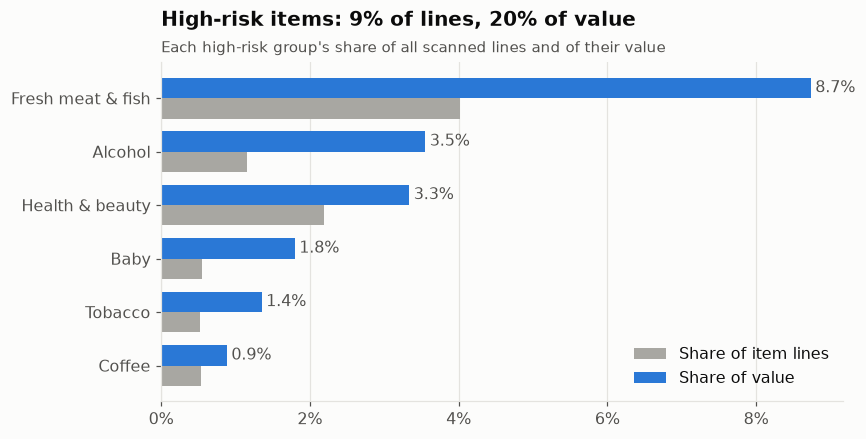

In [8]:
hr = risk.drop('Other').sort_values('share_value')
fig, ax = plt.subplots(figsize=(8, 4))
y = range(len(hr))
h = 0.38
b1 = ax.barh([i - h / 2 for i in y], hr.share_lines, h, color=GREY, label='Share of item lines')
b2 = ax.barh([i + h / 2 for i in y], hr.share_value, h, color=BLUE, label='Share of value')
ax.bar_label(b2, labels=[f'{v:.1%}' for v in hr.share_value], padding=3, color=TEXT_2)
ax.set_yticks(list(y), hr.index)
ax.xaxis.set_major_formatter(pct())
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
tot_l, tot_v = hr.share_lines.sum(), hr.share_value.sum()
ax.set_title(f'High-risk items: {tot_l:.0%} of lines, {tot_v:.0%} of value')
subtitle(ax, 'Each high-risk group\'s share of all scanned lines and of their value')
ax.legend(loc='lower right')
save(fig, '03_high_risk_categories')
fig

In [9]:
q('''
WITH b AS (
    SELECT basket_id, COUNT(*) AS n, MAX((risk_group IS NOT NULL)::INT) AS any_risk
    FROM scan_lines GROUP BY 1
)
SELECT AVG(any_risk) AS trips_with_any_high_risk,
       AVG(any_risk) FILTER (WHERE n >= 10) AS trips_10plus_with_any_high_risk
FROM b
''').round(3)

,trips_with_any_high_risk,trips_10plus_with_any_high_risk
0,0.447,0.719


## 4. Nectar price vs normal price: what is an unscanned item worth?

An item that leaves unscanned would have been paid for at the shopper's price. For a Nectar
member that is the Nectar price, so valuing loss at the normal shelf price overstates it.

In [10]:
disc = q('''
SELECT COALESCE(risk_group, 'Other') AS grp,
       AVG((member_discount > 0)::INT) AS share_lines_with_nectar_price,
       1 - SUM(nectar_value) / SUM(shelf_value) AS avg_discount,
       SUM(shelf_value) / SUM(nectar_value) - 1 AS overstatement_at_shelf_price
FROM scan_lines GROUP BY 1
UNION ALL
SELECT 'All items', AVG((member_discount > 0)::INT), 1 - SUM(nectar_value) / SUM(shelf_value),
       SUM(shelf_value) / SUM(nectar_value) - 1
FROM scan_lines
''').set_index('grp').sort_values('overstatement_at_shelf_price')
disc.round(3)

,share_lines_with_nectar_price,avg_discount,overstatement_at_shelf_price
grp,,,
Tobacco,0.006,0.001,0.001
Alcohol,0.009,0.001,0.001
Baby,0.457,0.088,0.097
Coffee,0.490,0.110,0.124
Health & beauty,0.382,0.121,0.138
All items,0.498,0.155,0.183
Other,0.508,0.155,0.184
Fresh meat & fish,0.558,0.241,0.318


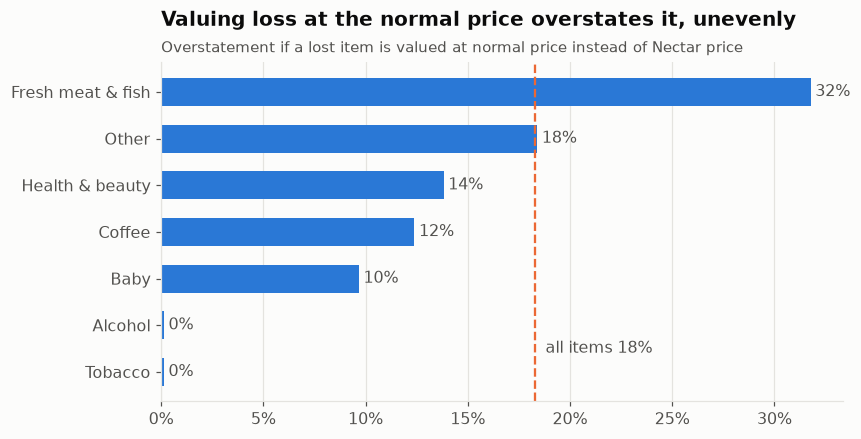

In [11]:
d = disc.drop('All items')
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(d.index, d.overstatement_at_shelf_price, color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f'{v:.0%}' for v in d.overstatement_at_shelf_price], padding=3, color=TEXT_2)
allv = disc.loc['All items', 'overstatement_at_shelf_price']
ax.axvline(allv, color=ORANGE, lw=1.5, ls='--')
ax.text(allv, 0.5, f'  all items {allv:.0%}', color=TEXT_2, va='center')
ax.xaxis.set_major_formatter(pct())
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.set_title('Valuing loss at the normal price overstates it, unevenly')
subtitle(ax, 'Overstatement if a lost item is valued at normal price instead of Nectar price')
save(fig, '04_nectar_price_overstatement')
fig

## 5. Multi-buy lines: the quantity risk

A line with quantity 4 can be scanned once while four leave the store.

In [12]:
q('''
SELECT AVG((quantity > 1)::INT) AS share_lines_multi_unit,
       SUM(quantity) FILTER (WHERE quantity > 1) / SUM(quantity) AS share_units_in_multi_lines,
       SUM(nectar_value) FILTER (WHERE quantity > 1) / SUM(nectar_value) AS share_value_in_multi_lines
FROM scan_lines
''').round(3)

,share_lines_multi_unit,share_units_in_multi_lines,share_value_in_multi_lines
0,0.199,0.39,0.27


## 6. When the store is busy: rescan capacity is not constant

In [13]:
hours = q('''
SELECT hour_of_day, COUNT(DISTINCT basket_id) AS trips FROM scan_lines GROUP BY 1 ORDER BY 1
''').set_index('hour_of_day')
day = hours.loc[7:22]
peak_share = day.loc[16:18, 'trips'].sum() / day.trips.sum()
print(f'4pm–7pm share of 7am–11pm trips: {peak_share:.1%}; busiest hour vs average: '
      f'{day.trips.max() / day.trips.mean():.2f}x')

4pm–7pm share of 7am–11pm trips: 29.9%; busiest hour vs average: 1.69x


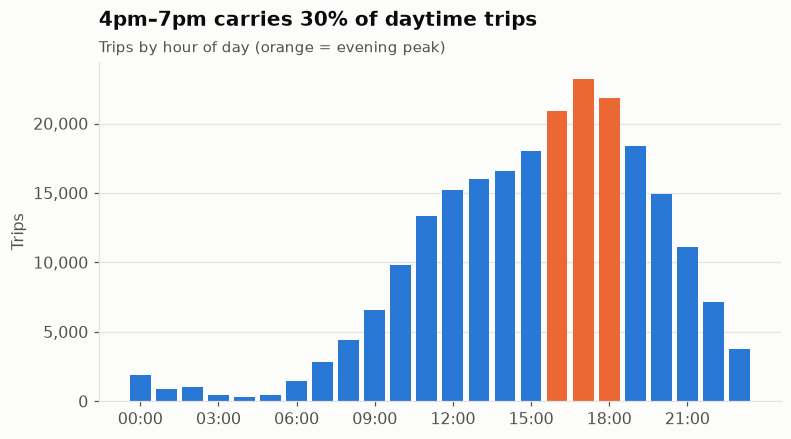

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = [ORANGE if 16 <= h <= 18 else BLUE for h in hours.index]
ax.bar(hours.index, hours.trips, color=colors, width=0.8)
ax.set_xticks(range(0, 24, 3), [f'{h:02d}:00' for h in range(0, 24, 3)])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _p: f'{x:,.0f}'))
ax.set_title(f'4pm–7pm carries {peak_share:.0%} of daytime trips')
subtitle(ax, 'Trips by hour of day (orange = evening peak)')
ax.set_ylabel('Trips')
save(fig, '05_trips_by_hour')
fig

## 7. Shopper history: can a Nectar-linked trust score work?

A trust score needs history. It also matters whether history belongs to a store or to the
member: if shoppers use several stores, only a Nectar-linked, member-level score sees it all.

In [15]:
hist = q('''
WITH b AS (SELECT member_id, basket_id, MIN(day) AS d FROM scan_lines GROUP BY 1, 2),
r AS (SELECT *, ROW_NUMBER() OVER (PARTITION BY member_id ORDER BY d, basket_id) - 1 AS prior_trips FROM b)
SELECT prior_trips FROM r
''')
members = q('''
WITH ms AS (SELECT member_id, store_id, COUNT(DISTINCT basket_id) AS n FROM scan_lines GROUP BY 1, 2)
SELECT member_id, SUM(n) AS trips, COUNT(*) AS stores, MAX(n) * 1.0 / SUM(n) AS main_store_share
FROM ms GROUP BY 1
''')
pd.Series({
    'median trips per member (86 weeks)': members.trips.median(),
    'share of trips with 10+ earlier trips': (hist.prior_trips >= 10).mean(),
    'share of trips that are a first visit': (hist.prior_trips == 0).mean(),
    'median stores used per member': members.stores.median(),
    'share of members using 2+ stores': (members.stores > 1).mean(),
    'share of members with <80% of trips at main store': (members.main_store_share < 0.8).mean(),
}).round(3)

median trips per member (86 weeks)                   67.000
share of trips with 10+ earlier trips                 0.895
share of trips that are a first visit                 0.011
median stores used per member                         4.000
share of members using 2+ stores                      0.908
share of members with <80% of trips at main store     0.562
dtype: float64

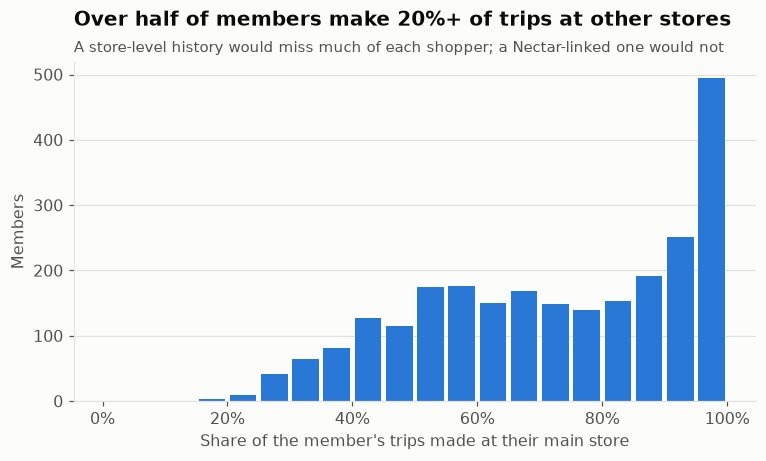

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(members.main_store_share, bins=20, range=(0, 1), color=BLUE, rwidth=0.85)
ax.xaxis.set_major_formatter(pct())
ax.set_xlabel("Share of the member's trips made at their main store")
ax.set_ylabel('Members')
ax.set_title('Over half of members make 20%+ of trips at other stores')
subtitle(ax, 'A store-level history would miss much of each shopper; a Nectar-linked one would not')
save(fig, '06_main_store_share')
fig

## Findings

| # | Finding | Decision for SmartShop |
|---|---|---|
| 1 | Median trip has 5 item lines (7 units); 15% of trips have 20+ lines | Full rescans vary hugely in effort: cost a rescan in minutes per item, not per trip |
| 2 | The 3 most valuable items hold 46% of value in 10–19-line baskets vs 23% for 3 random items, and 27% vs 10% at 20+ lines | Targeted partial rescans are worth building even before any model (week 7) |
| 3 | High-risk categories are 9% of lines but 20% of value, at 2–4x the price per unit; 72% of trips with 10+ lines contain one | They anchor the simulator's deliberate-skip behaviour and the risk features |
| 4 | Half of lines carry a Nectar price; valuing loss at the normal price overstates it by 18% overall and 32% for fresh meat, but barely at all for alcohol and tobacco | Value every lost item at the shopper's own price, line by line |
| 5 | 20% of lines are multi-buys, holding 39% of units | Simulate quantity under-declaring; check quantities in targeted rescans |
| 6 | 4pm–7pm carries 30% of daytime trips; the busiest hour is 1.7x the average | Rescan capacity is a constraint that moves; it enters the policy (v2: queue-aware) |
| 7 | 89% of trips come with 10+ earlier trips by the same member; 91% of members use 2+ stores, and 56% make under 80% of trips at their main store | A trust score has history for most trips, but only if it is member-level via Nectar, not per store |

**Caveat:** the panel is loyal, card-holding households, so repeat-visit figures are an upper
bound for SmartShop overall. New and non-Nectar shoppers get the standard rescan rate (no
history is not a reason to check more), and they are simulated in week 3.